# Entrenamiento y optimización de modelos
### Predicción de intención de compra en tiendas online

**Objetivo:** entrenar, optimizar y comparar cuatro algoritmos de clasificación para identificar y priorizar sesiones con mayor probabilidad de compra.

Hemos estudiado cuatro enfoques de aprendizaje automático:

1. **Regresión logística:** modelo lineal.
2. **Random Forest:** conjunto de árboles mediante bagging.
3. **MLP:** red neuronal multicapa.
4. **CatBoost:** árboles potenciados mediante Gradient Boosting.

La comparación utilizará validación cruzada estratificada, tomando **Average Precision (AP)** como métrica principal.

## 1. Metodología experimental

### 1.1. Configuración y reproducibilidad

Todos los experimentos utilizarán la semilla 42 y la misma división estratificada del dataset.

El preprocesamiento lo hemos adaptado a cada familia de algoritmos, manteniendo las mismas características predictoras y particiones de validación.

In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from catboost import CatBoostClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

### 1.2. Preparación de los datos

Hemos reproducido el procedimiento establecido en el EDA:

- Eliminación de registros duplicados.
- División estratificada del 80 % para entrenamiento y del 20 % para prueba.
- Semilla 42.

La validación cruzada y la optimización la hemos hecho solo sobre el conjunto de entrenamiento.

Inicialmente hemos mantenido las 17 características predictoras, incluida `PageValues`.

In [4]:
RAIZ = Path.cwd().resolve()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

RUTA_CSV = RAIZ / "data" / "raw"/ "online_shoppers_intention.csv"

datos = pd.read_csv(RUTA_CSV)

filas_originales = len(datos)
datos = datos.drop_duplicates().reset_index(drop=True)

X = datos.drop(columns="Revenue")
y = datos["Revenue"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Sesiones originales: {filas_originales:,}")
print(f"Duplicados eliminados: {filas_originales - len(datos)}")
print(f"Entrenamiento: {len(X_train):,}")
print(f"Prueba: {len(X_test):,}")
print(f"Características: {X_train.shape[1]}")
print(f"Compras en entrenamiento: {y_train.mean():.2%}")

Sesiones originales: 12,330
Duplicados eliminados: 125
Entrenamiento: 9,764
Prueba: 2,441
Características: 17
Compras en entrenamiento: 15.63%


### 1.3. Validación cruzada y métricas

Para evaluar los distintos algoritmos con las mismas condiciones, hemos utilizado una validación cruzada estratificada de cinco particiones. Así mantenemos una proporción parecida de compradores y no compradores en cda partición.

La métrica principal será **Average Precision (AP)**, que resume el rendimiento de la relación entre Precision y Recall para distintos umbrales. Es especialmente útil en problemas desequilibrados y permite evaluar la capacidad de priorizar sesiones compradoras sin depender de un único umbral.

También vamos a tener en cuenta otras métricas para comparar los resutlados:

- **ROC AUC:** mide la capacidad del modelo para distingui entre compradores y no compradores.
- **Precision:** indica cuántas de las sesiones que el modelo predice como comrpa terminan siendo realmente compras.
- **Recall:** mide cuántas de las compras reales consigue identificar el modelo.
- **F1:** media harmónica entre Precisión y Recall.

Al principio vamos a utilizar el umbral predeterminado de 0,5 para clasificar las sesiones como compra o no compra. Más adelante estudiaremos cómo ajustar este umbral para mejorar los resultados.

In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

metricas = {
    "AP": "average_precision",
    "ROC AUC": "roc_auc",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1"
}

## 2. Evaluación de los modelos de referencia

### 2.1. Preprocesamiento según el algoritmo

Cada algoritmo necesita un preprocesamiento diferente para poder trabajar correctamente con los datos:
- **Regresión logística y MLP:** escalamos las variabels numéricas utilizando StandardScaler y aplicamos One-Hot Encoding a las variables categóricas.
- **Random Forest:** aplicamos One-Hot Enconding a las variables categóricas pero no necesitamos escalar las numéricas.
- **CatBoost:** puede trabajar directamente con las variables categóricas.

Todos los transformadores de scrikit-learn se incluyen dentro de sus respectivos Pipeline. Así conseguimos que el preprocesamiento se ajuste solo con los datos de entrenamiento de cada partición, evitando utilizar información del conjunto de validación antes de tiempo.

In [6]:
variables_categoricas = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

variables_numericas = [
    columna for columna in X_train.columns
    if columna not in variables_categoricas
]

# Preprocesamiento para regresión logística y MLP
preprocesador_escalado = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), variables_numericas),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas
        )
    ]
)

# Preprocesamiento para Random Forest
preprocesador_arboles = ColumnTransformer(
    transformers=[
        ("num", "passthrough", variables_numericas),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            variables_categoricas
        )
    ]
)

# Preprocesamiento para CatBoost 
# recibe las categorías como texto
X_train_cat = X_train.copy()

for columna in variables_categoricas:
    X_train_cat[columna] = X_train_cat[columna].astype(str)

print(f"Numéricas: {len(variables_numericas)}")
print(f"Categóricas: {len(variables_categoricas)}")

Numéricas: 10
Categóricas: 7


### 2.2. Configuraciones iniciales

Hemos definido una configuración inicial para cada algoritmo sin realizar todavía ningún ajuste de hiperparámetros.

En esta primera fase no aplicamos técnicas para equilibrar las clases ni añadimos nuevas variables al conjunto.

Estas configuraciones nos servirán como punto de partida para comparar los resultados iniciales con los que obtengamos después de optimizar los modelos.

In [15]:
# 1. Regresión logística
modelo_lr = Pipeline([
    ("preprocesamiento", preprocesador_escalado),
    ("clasificador", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

# 2. Random Forest
modelo_rf = Pipeline([
    ("preprocesamiento", preprocesador_arboles),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# 3. Red neuronal MLP
modelo_mlp = Pipeline([
    ("preprocesamiento", preprocesador_escalado),
    ("clasificador", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        max_iter=400,
        early_stopping=True,
        random_state=RANDOM_STATE
    ))
])

# CatBoost: las variables categóricas se indicarán al entrenar
modelo_catboost = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    random_seed=RANDOM_STATE,
    thread_count=4,
    verbose=False,
    allow_writing_files=False
)

# Actualizamos la referencia del diccionario
modelos["CatBoost"] = modelo_catboost

# los agrupamos en un diccionario para evaluarlos conjuntamente
modelos = {
    "Regresión logística": modelo_lr,
    "Random Forest": modelo_rf,
    "MLP": modelo_mlp,
    "CatBoost": modelo_catboost
}

In [16]:
from sklearn.base import clone

print("cat_features:", modelos["CatBoost"].get_params().get("cat_features"))

clone(modelos["CatBoost"])

print("CatBoost se puede clonar correctamente.")

cat_features: None
CatBoost se puede clonar correctamente.


### 2.3. Evaluación inicial mediante validación cruzada

Hemos evaluado los cuatro modelos utilizando las mismas cinco particiones estratificdas y sus configuraciones iniciales.

Para cada modelo hemos guardado los resultados de cada partición para poder comparar su rendimiento medio y cuánto varían los resultados entre las distintas particiones.

In [17]:
resultados = []

for nombre, modelo in modelos.items():

    print(f"Evaluando {nombre}...")

    X_cv = X_train_cat if nombre == "CatBoost" else X_train

    # CatBoost recibe las categorías durante el entrenamiento
    parametros_fit = (
        {"cat_features": variables_categoricas}
        if nombre == "CatBoost"
        else {}
    )

    evaluacion = cross_validate(
        modelo,
        X_cv,
        y_train,
        cv=cv,
        scoring=metricas,
        params=parametros_fit,
        n_jobs=1,
        error_score="raise"
    )

    for fold in range(cv.get_n_splits()):
        fila = {
            "Modelo": nombre,
            "Fold": fold + 1
        }

        for metrica in metricas:
            fila[metrica] = evaluacion[f"test_{metrica}"][fold]

        resultados.append(fila)

resultados_folds = pd.DataFrame(resultados)

display(resultados_folds.round(3))

Evaluando Regresión logística...
Evaluando Random Forest...
Evaluando MLP...
Evaluando CatBoost...


,Modelo,Fold,AP,ROC AUC,Precision,Recall,F1
0,Regresión logística,1,0.650,0.890,0.758,0.389,0.514
1,Regresión logística,2,0.594,0.865,0.694,0.328,0.445
2,Regresión logística,3,0.632,0.898,0.732,0.393,0.512
3,Regresión logística,4,0.648,0.891,0.753,0.400,0.522
4,Regresión logística,5,0.653,0.899,0.781,0.351,0.484
5,Random Forest,1,0.732,0.924,0.765,0.510,0.612
6,Random Forest,2,0.724,0.918,0.770,0.482,0.593
7,Random Forest,3,0.757,0.928,0.778,0.518,0.622
8,Random Forest,4,0.777,0.931,0.778,0.551,0.645
9,Random Forest,5,0.745,0.927,0.814,0.502,0.621


In [18]:
# Resumen de los modelos iniciales

resumen_base = (
    resultados_folds
    .groupby("Modelo")
    .agg(
        AP_media=("AP", "mean"),
        AP_desv=("AP", "std"),
        ROC_AUC=("ROC AUC", "mean"),
        Precision=("Precision", "mean"),
        Recall=("Recall", "mean"),
        F1=("F1", "mean")
    )
    .sort_values("AP_media", ascending=False)
)

display(
    resumen_base.style
    .format("{:.3f}")
    .background_gradient(
        subset=["AP_media"],
        cmap="Blues"
    )
)

,AP_media,AP_desv,ROC_AUC,Precision,Recall,F1
Modelo,,,,,,
Random Forest,0.747,0.021,0.926,0.781,0.512,0.618
CatBoost,0.742,0.025,0.930,0.736,0.588,0.654
MLP,0.702,0.018,0.911,0.712,0.554,0.622
Regresión logística,0.636,0.024,0.889,0.744,0.372,0.496


### 2.4. Comparación visual de Average Precision

Hemos representado los valores de Average Precision obtenidos por los cuatro algoritmos en las cinco particiones de validación cruzada.

En el gráfico las cajas nos permiten ver cómo varían los resultados de cada modelo y los puntos nos enseñan el valor obtenido de cada fold.

Hemos añadido también una línea de referencia que indica la proporción de compradores en el conjunto de entrenamiento. Esto nos permite comprar los resultados de los modelos con un calor de referencia inicial.

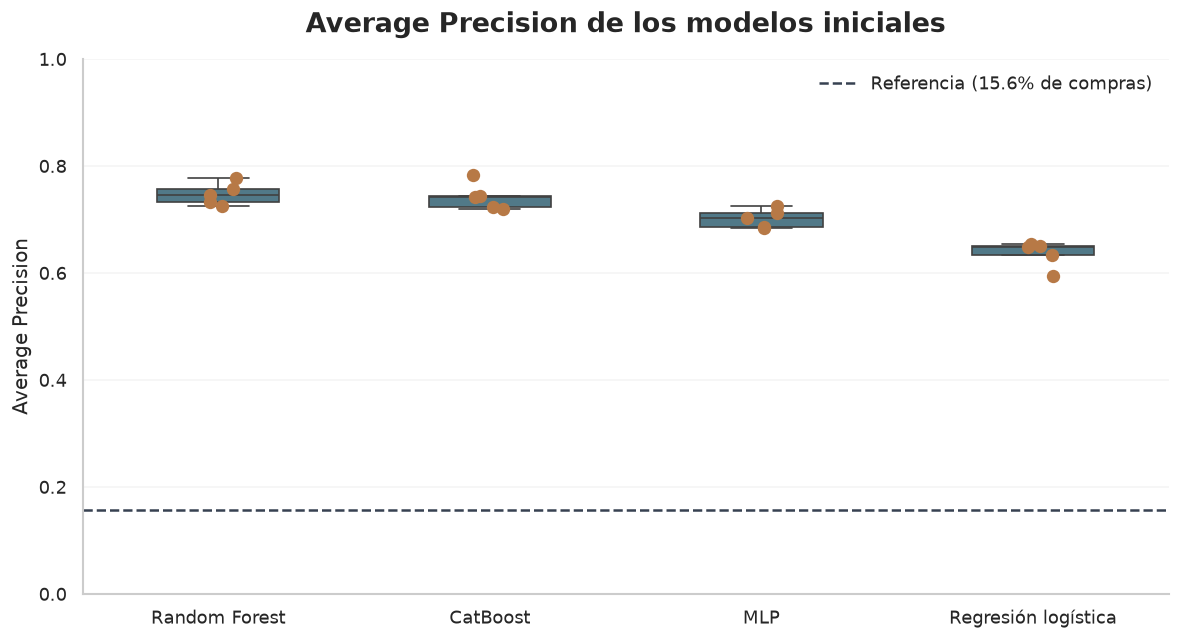

In [19]:
orden = resumen_base.index.tolist()

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.boxplot(
    data=resultados_folds,
    x="Modelo",
    y="AP",
    order=orden,
    color="#487D91",
    width=0.45,
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=resultados_folds,
    x="Modelo",
    y="AP",
    order=orden,
    color="#B77946",
    size=8,
    jitter=0.08,
    ax=ax
)

ax.axhline(
    y_train.mean(),
    color="#374151",
    linestyle="--",
    linewidth=1.5,
    label=f"Referencia ({y_train.mean():.1%} de compras)"
)

ax.set_title(
    "Average Precision de los modelos iniciales",
    fontsize=16,
    pad=16
)

ax.set_xlabel("")
ax.set_ylabel("Average Precision")
ax.set_ylim(0, 1)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest y CatBoost** tienen los mejores resultados en Average Precision (0,747 y 0,742). La diferencia entre ambos es muy pequeña por lo que todavía no podemos decir que uno sea mejor que otro.
- **CatBoost** obtiene el mejor ROC AUC (0,930), Recall (0,588) y F1 (0,654). Random Forest tiene la mayor Precision (0,781).
- **MLP** consigue resultados intermedios (AP = 0,702), mientras que la regresión logística tiene el menor rendimiento (AP = 0,636).
- Los cuatro modelos representan resultados bastante estables entre los distintos folds aunque las pequeñas diferencias en Average Precision tenemos que interpretarlas con cuidado.

**Decisión:** vamos a optimizar los cuatro algoritmos utilizando Average Precision como métrica principal. Así podremos comprobar si los resultados se mantienen después de ajustar sus hiperparámetros.

## 3. Optimización de hiperparámetros

Después de evaluar los mdoelos con sus configuraciones iniciales vamos a intentar mejorar sus resultados ajustando sus hiperparámetros mediante la validación cruzada estratificada.

Hemos utilizado Average Precision como métrica prinicipal para elegir las mejores configuraciones y depués hemos comparado los resultados con los modelos iniciales del apartado anterior.

### 3.1. Regresión logística

Para la regresión logística vamos a probar diferentes valores de dos hiperparámetros:

- **C:** controla la intensidad de la regularización. Cuanto menor es su valor, mayor es la regularización.

- **l1_ratio:** determina el tipo de regularización que utilizamos. El valor 0 corresponde a L2 y el valor 1 a L1. La regularización L1 puede hacer que algunos coeficientes pasen a ser cero.

Utilizamos el solver `liblinear` que nos permite trabajr con ambos tipos de regularización.

La búsqueda se realizará solo con el conjunto de entrenamiento y con los mismos cinco folds.

In [21]:
from sklearn.model_selection import GridSearchCV


parametros_lr = {
    "clasificador__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "clasificador__l1_ratio": [0.0, 1.0],
    "clasificador__solver": ["liblinear"]
}

busqueda_lr = GridSearchCV(
    estimator=modelo_lr,
    param_grid=parametros_lr,
    scoring=metricas,
    refit="AP",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_lr.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_lr.best_params_)

print(f"\nAP inicial: {resumen_base.loc['Regresión logística', 'AP_media']:.3f}")
print(f"AP optimizado (CV): {busqueda_lr.best_score_:.3f}")

print("Mejores hiperparámetros:")
print(busqueda_lr.best_params_)

print(f"\nAP inicial: {resumen_base.loc['Regresión logística', 'AP_media']:.3f}")
print(f"AP optimizado (CV): {busqueda_lr.best_score_:.3f}")

Mejores hiperparámetros:
{'clasificador__C': 0.01, 'clasificador__l1_ratio': 1.0, 'clasificador__solver': 'liblinear'}

AP inicial: 0.636
AP optimizado (CV): 0.651
Mejores hiperparámetros:
{'clasificador__C': 0.01, 'clasificador__l1_ratio': 1.0, 'clasificador__solver': 'liblinear'}

AP inicial: 0.636
AP optimizado (CV): 0.651


#### Resultados de la búsqueda

Hemos representado en un mapa de calro los valores medio de Average Precision que hemos obtenido con las diferentes combinaciones de regularización y C.

Este gráfico no permite ver qué configuraciones nos dan mejores resultados y mejor AP. También podemos ver si los resutlados siguen mejorando en los extremos, lo que nos ayudaría a decidir si merece la pena ampliar la bísqueda. 

La configuración con mayor AP aparece resaltada.

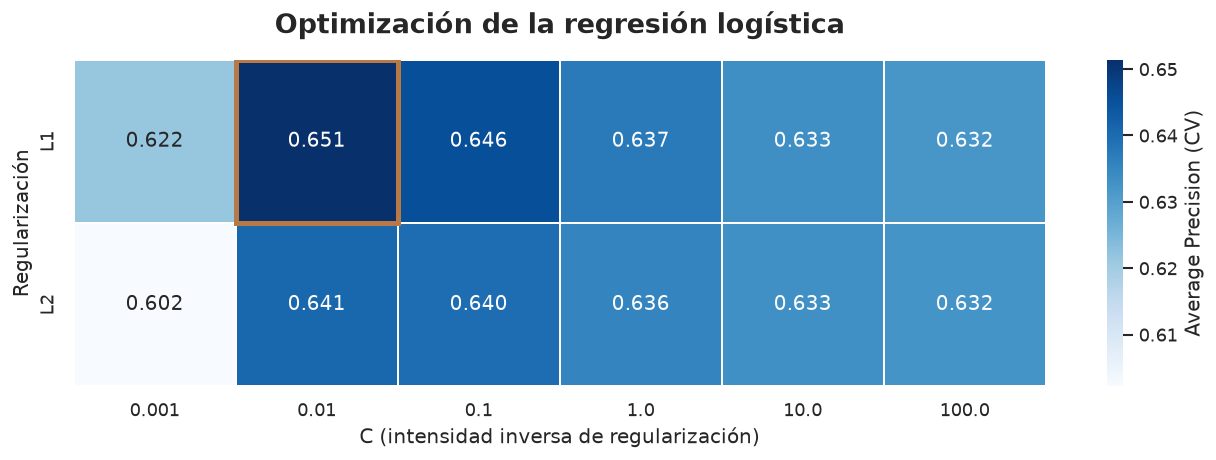

In [24]:
resultados_lr = pd.DataFrame(busqueda_lr.cv_results_)

resultados_lr["C"] = resultados_lr[
    "param_clasificador__C"
].astype(float)

resultados_lr["Regularización"] = (
    resultados_lr["param_clasificador__l1_ratio"]
    .astype(float)
    .map({0.0: "L2", 1.0: "L1"})
)

# Matriz: filas = regularización, columnas = C
mapa_ap = resultados_lr.pivot(
    index="Regularización",
    columns="C",
    values="mean_test_AP"
)

mapa_ap = (
    mapa_ap
    .reindex(["L1", "L2"])
    .sort_index(axis=1)
)

fig, ax = plt.subplots(figsize=(11, 4))

sns.heatmap(
    mapa_ap,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Average Precision (CV)"},
    ax=ax
)

# Resaltar la mejor combinación
mejor_fila, mejor_columna = np.unravel_index(
    np.nanargmax(mapa_ap.to_numpy()),
    mapa_ap.shape
)

ax.add_patch(
    plt.Rectangle(
        (mejor_columna, mejor_fila),
        1, 1,
        fill=False,
        edgecolor="#B77946",
        linewidth=3
    )
)

ax.set_title(
    "Optimización de la regresión logística",
    fontsize=16,
    pad=16
)

ax.set_xlabel("C (intensidad inversa de regularización)")
ax.set_ylabel("Regularización")

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración es la que utiliza regularización **L1 con C = 0,01**, con un AP de **0,651**, frente al 0,636 inicial.
- Los mejores resultados tienen valores intermedios de C. Cuando regularización es muy alta (C = 0,001) o muy baja (C ≥ 1) el rendimiento empeora.
- L1 supera ligeramente a L2 en las configuraciones más competitivas.

**Decisión:** nos quedamos con L1 con C = 0,01 como mejor configuración de regresión logística. Como el mejor resultado está dentro del intervalo de valores que hemos probado no es necesario ampliar la búsqueda.

### 3.2. Random Forest

Random Forest combina varios árboles de decisión. Cada árbol se entrena con diferentes muestras y subconjuntos de características, para posteriormente combinar sus predicciones y obtener el resultado final.

Para intentar mejorar su rendimiento vamos a probar diferentes valores de cuatro hiperparámetros:
- **n_estimators:** número de árboles del modelo.
- **max_depth:** profundidad máxima de cada árbol.
- **min_samples_leaf:** número mínimo de observaciones por hoja. Esto ayuda a que los árboles no sean demasiado complejos.
- **max_features:** cuántas características se tienen en caunta al buscar cada división. Esto afecta a la diversidad entre los árboles.

Para encontrar la mejor combinación hemos utilizado GridSearchCV con cinco folds estratificados, seleccionando la configuración que tenga mayor Average Precision.

In [29]:
parametros_rf = {
    "clasificador__n_estimators": [150, 300],
    "clasificador__max_depth": [10, 20, None],
    "clasificador__min_samples_leaf": [1, 2, 4, 8],
    "clasificador__max_features": ["sqrt", 0.5]
}

busqueda_rf = GridSearchCV(
    estimator=modelo_rf,
    param_grid=parametros_rf,
    scoring=metricas,
    refit="AP",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_rf.best_params_)

print(f"\nAP inicial: {resumen_base.loc['Random Forest', 'AP_media']:.3f}")
print(f"AP optimizado (CV): {busqueda_rf.best_score_:.3f}")

Mejores hiperparámetros:
{'clasificador__max_depth': 10, 'clasificador__max_features': 0.5, 'clasificador__min_samples_leaf': 8, 'clasificador__n_estimators': 300}

AP inicial: 0.747
AP optimizado (CV): 0.755


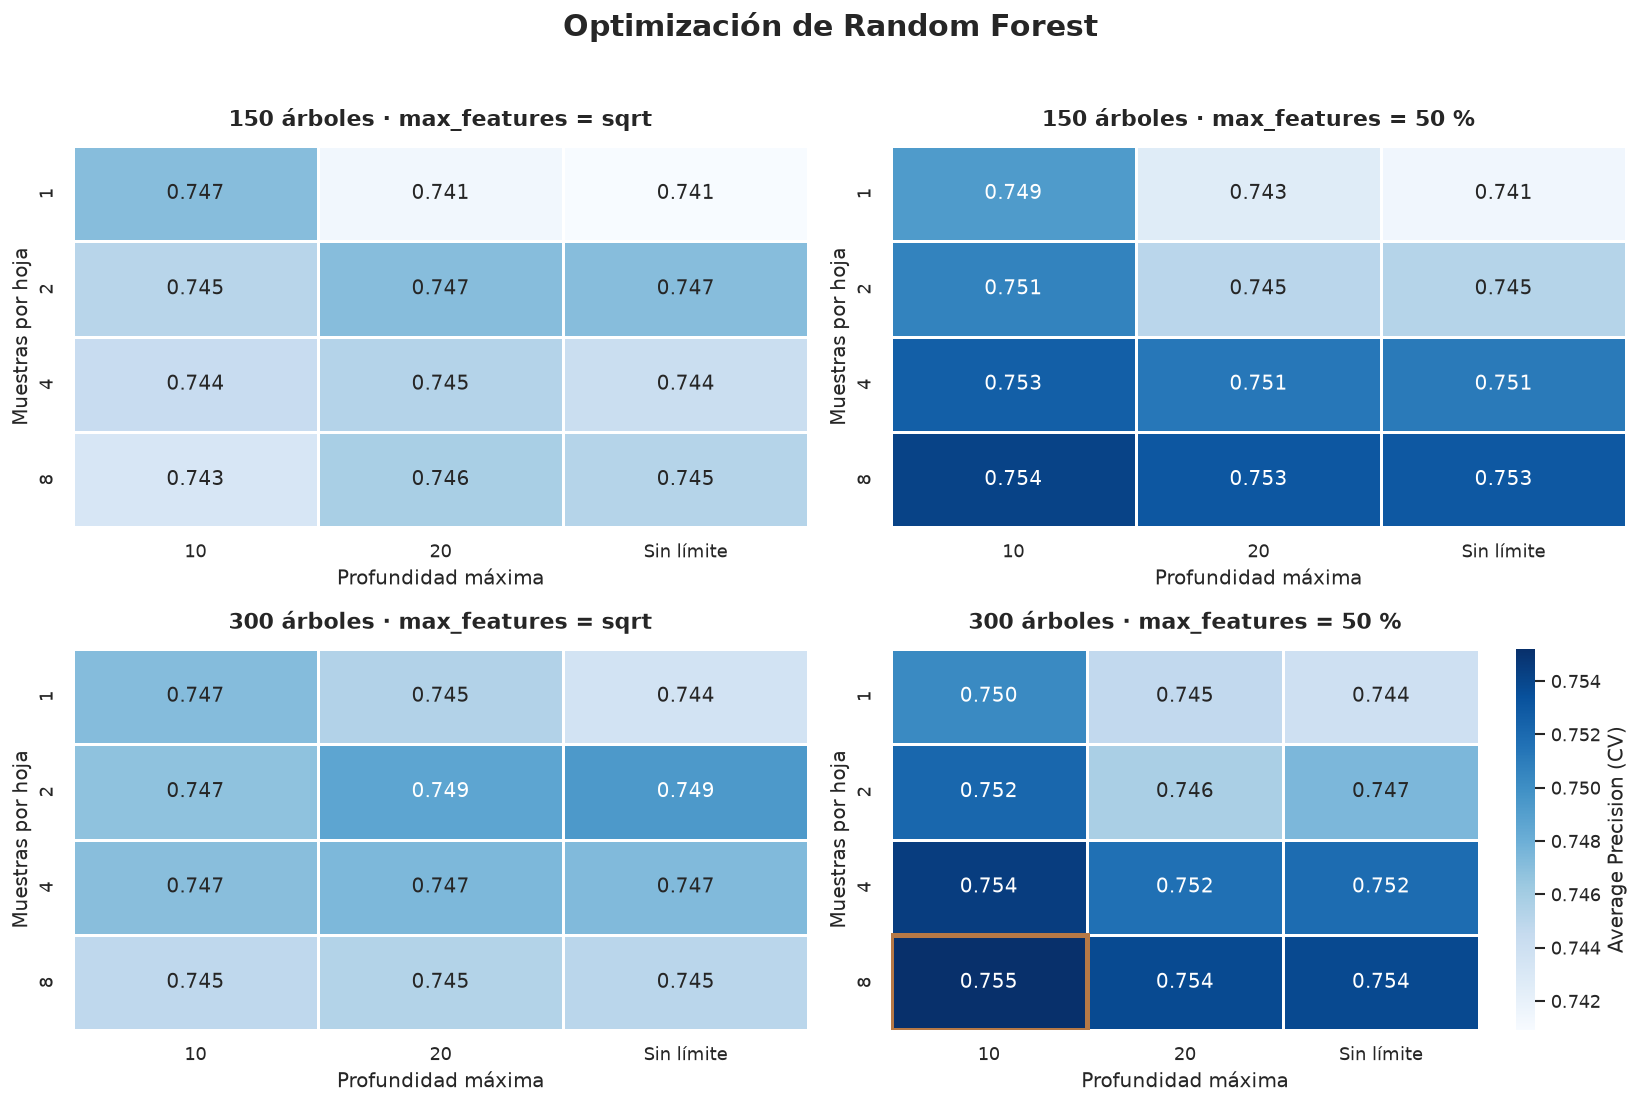

In [30]:
resultados_rf = pd.DataFrame(busqueda_rf.cv_results_)

resultados_rf["Árboles"] = (
    resultados_rf["param_clasificador__n_estimators"].astype(int)
)

resultados_rf["Profundidad"] = (
    resultados_rf["param_clasificador__max_depth"]
    .map(lambda x: "Sin límite" if x is None else str(x))
)

resultados_rf["Muestras por hoja"] = (
    resultados_rf["param_clasificador__min_samples_leaf"].astype(int)
)

resultados_rf["Características"] = (
    resultados_rf["param_clasificador__max_features"]
    .map(lambda x: "sqrt" if x == "sqrt" else "50 %")
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

combinaciones = [
    (150, "sqrt"),
    (150, "50 %"),
    (300, "sqrt"),
    (300, "50 %")
]

vmin = resultados_rf["mean_test_AP"].min()
vmax = resultados_rf["mean_test_AP"].max()

mejor = busqueda_rf.best_params_

for i, (ax, (arboles, caracteristicas)) in enumerate(
    zip(axes.flat, combinaciones)
):
    subset = resultados_rf[
        (resultados_rf["Árboles"] == arboles) &
        (resultados_rf["Características"] == caracteristicas)
    ]

    mapa = subset.pivot(
        index="Muestras por hoja",
        columns="Profundidad",
        values="mean_test_AP"
    )

    mapa = mapa.reindex(
        index=[1, 2, 4, 8],
        columns=["10", "20", "Sin límite"]
    )

    sns.heatmap(
        mapa,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        linewidths=0.7,
        linecolor="white",
        cbar=(i == 3),
        cbar_kws={"label": "Average Precision (CV)"},
        ax=ax
    )

    # Destacar la mejor configuración global
    if (
        mejor["clasificador__n_estimators"] == arboles
        and (
            ("sqrt" if mejor["clasificador__max_features"] == "sqrt"
             else "50 %") == caracteristicas
        )
    ):
        fila = [1, 2, 4, 8].index(
            mejor["clasificador__min_samples_leaf"]
        )

        profundidad = (
            "Sin límite"
            if mejor["clasificador__max_depth"] is None
            else str(mejor["clasificador__max_depth"])
        )

        columna = ["10", "20", "Sin límite"].index(profundidad)

        ax.add_patch(
            plt.Rectangle(
                (columna, fila), 1, 1,
                fill=False,
                edgecolor="#B77946",
                linewidth=3
            )
        )

    ax.set_title(
        f"{arboles} árboles · max_features = {caracteristicas}",
        fontsize=13,
        pad=12
    )

    ax.set_xlabel("Profundidad máxima")
    ax.set_ylabel("Muestras por hoja")

fig.suptitle(
    "Optimización de Random Forest",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración tiene un **AP de 0,755**, frente al 0,747 inicial. Esta usa 300 árboles, max_features=0.5, max_depth=10 y min_samples_leaf=8.
- Las configuraciones con max_features=0.5 suelen ser mejores que las que utilizan sqrt.
- Aumentar el número de árboles de 150 a 300 apenas modifica el rendimiento.
- Los mejores resultados se consiguen con árboles poco profundos y un mínimo de 4-8 observaciones por hoja.

**Decisión:** ponemos 300 árboles y max_features=0.5, y hacemos una búsqueda más precisa de max_depth y min_samples_leaf.

#### Refinamiento de hiperparámetros

En lLa primera búsqueda hemos visto que aumentar el número de árboles apenas modifica el rendimiento y que max_features=0.5 da buenos resultados.

Por eso, vamos a mantener esos dos parámetros fijos y ajustar el resto: la profundidad máxima y el número mínimo de observaciones por hoja.

Probamos profundidades entre 5 y 15 y tamaños mínimos de hoja entre 4 y 16, manteniendo fijos el número de árboles y max_features.

In [31]:
from sklearn.base import clone

modelo_rf_refinado = clone(modelo_rf).set_params(
    clasificador__n_estimators=300,
    clasificador__max_features=0.5
)

parametros_rf_refinados = {
    "clasificador__max_depth": [5, 8, 10, 15],
    "clasificador__min_samples_leaf": [4, 8, 12, 16]
}

busqueda_rf_refinada = GridSearchCV(
    estimator=modelo_rf_refinado,
    param_grid=parametros_rf_refinados,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_rf_refinada.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_rf_refinada.best_params_)

print(f"\nAP inicial: {resumen_base.loc['Random Forest', 'AP_media']:.3f}")
print(f"AP primera búsqueda: {busqueda_rf.best_score_:.3f}")
print(f"AP refinamiento: {busqueda_rf_refinada.best_score_:.3f}")

Mejores hiperparámetros:
{'clasificador__max_depth': 8, 'clasificador__min_samples_leaf': 8}

AP inicial: 0.747
AP primera búsqueda: 0.755
AP refinamiento: 0.756


#### Resultados del refinamiento

Hemos representado en un mapa de calor las 16 configuraciones que hemos probado. Así podemos ver gráficamente qué combinaciones nos dan unos mejores resultados y podemos ver su hay alguna zona en la que merezca la pena seguir ajustando parámetros.

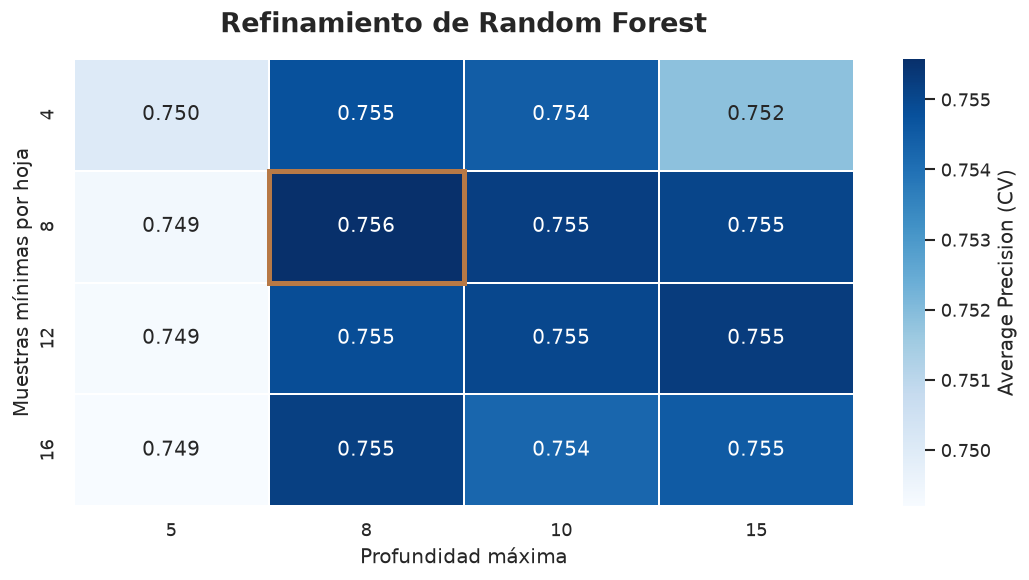

In [32]:
resultados_refinados = pd.DataFrame(
    busqueda_rf_refinada.cv_results_
)

mapa_rf_refinado = resultados_refinados.pivot(
    index="param_clasificador__min_samples_leaf",
    columns="param_clasificador__max_depth",
    values="mean_test_score"
)

mapa_rf_refinado = mapa_rf_refinado.reindex(
    index=[4, 8, 12, 16],
    columns=[5, 8, 10, 15]
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(
    mapa_rf_refinado,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Average Precision (CV)"},
    ax=ax
)

mejor_fila, mejor_columna = np.unravel_index(
    np.nanargmax(mapa_rf_refinado.to_numpy()),
    mapa_rf_refinado.shape
)

ax.add_patch(
    plt.Rectangle(
        (mejor_columna, mejor_fila),
        1, 1,
        fill=False,
        edgecolor="#B77946",
        linewidth=3
    )
)

ax.set_title(
    "Refinamiento de Random Forest",
    fontsize=16,
    pad=16
)

ax.set_xlabel("Profundidad máxima")
ax.set_ylabel("Muestras mínimas por hoja")

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración es con **max_depth=8** y **min_samples_leaf=8**, con un AP de **0,756**.
- Las profundidades entre 8 y 15 y los tamaños de hoja entre 4 y 16 tienen resultados muy similares.
- Esta segunda búsqueda casi no mejora el AP anterior (0,755), por lo que podemos decir los resultados muestran una región de rendimiento similar dentro del espacio de hiperparámetros evaluado.

**Decisión:** seleccionamos la configuración con 300 árboles, max_features=0.5, max_depth=8 y min_samples_leaf=8.
No vamos a hcaer más búsquedas para este algoritmo.

### 3.3. Perceptrón multicapa (MLP)

El MLP es una red neuronal que aprende relaciones no lineales mediante varias capas de neuronas conectadas entre sí.

Vamos a optimizar tres hiperparámetros:

- **hidden_layer_sizes:** número de capas ocultas tiene la red y cuántas neuronas hay en cada una.

- **learning_rate_init:** controla el tamaño de los pasos que da el algoritmo para ajustar los pesos de la red durante el entrenamiento.

- **alpha:** constorla la intensidad de la regularización L2, que ayuda a controlar el sobreajuste.

Mantendremos la activación ReLU, el optimizador Adam y la parada temprana de la configuración inicial.

Para utilizar la mejor combinación usaremos GridSearchCV con cinco folds estratificados y Average Precision como criterio de selección.

In [34]:
parametros_mlp = {
    "clasificador__hidden_layer_sizes": [
        (16,), (32, 16), (64, 32)
    ],
    "clasificador__learning_rate_init": [
        0.0003, 0.001, 0.003
    ],
    "clasificador__alpha": [
        0.0001, 0.01
    ]
}

busqueda_mlp = GridSearchCV(
    estimator=modelo_mlp,
    param_grid=parametros_mlp,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_mlp.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_mlp.best_params_)

print(f"\nAP inicial: {resumen_base.loc['MLP', 'AP_media']:.3f}")
print(f"AP optimizado (CV): {busqueda_mlp.best_score_:.3f}")

Mejores hiperparámetros:
{'clasificador__alpha': 0.01, 'clasificador__hidden_layer_sizes': (64, 32), 'clasificador__learning_rate_init': 0.003}

AP inicial: 0.702
AP optimizado (CV): 0.713


#### Resultados de la búsqueda

Hemos representado los resultados mediante tres mapas de calor, uno por cada tasa de aprendizaje.

En cada mapa comparamos las arquitecturas y los valores de regularización, utilizando una escala del mismo color para poder comprarlos.

Esto nos deja ver cuáles son las mejores configuraciones y comprobar si conviene cambiar algún rango.

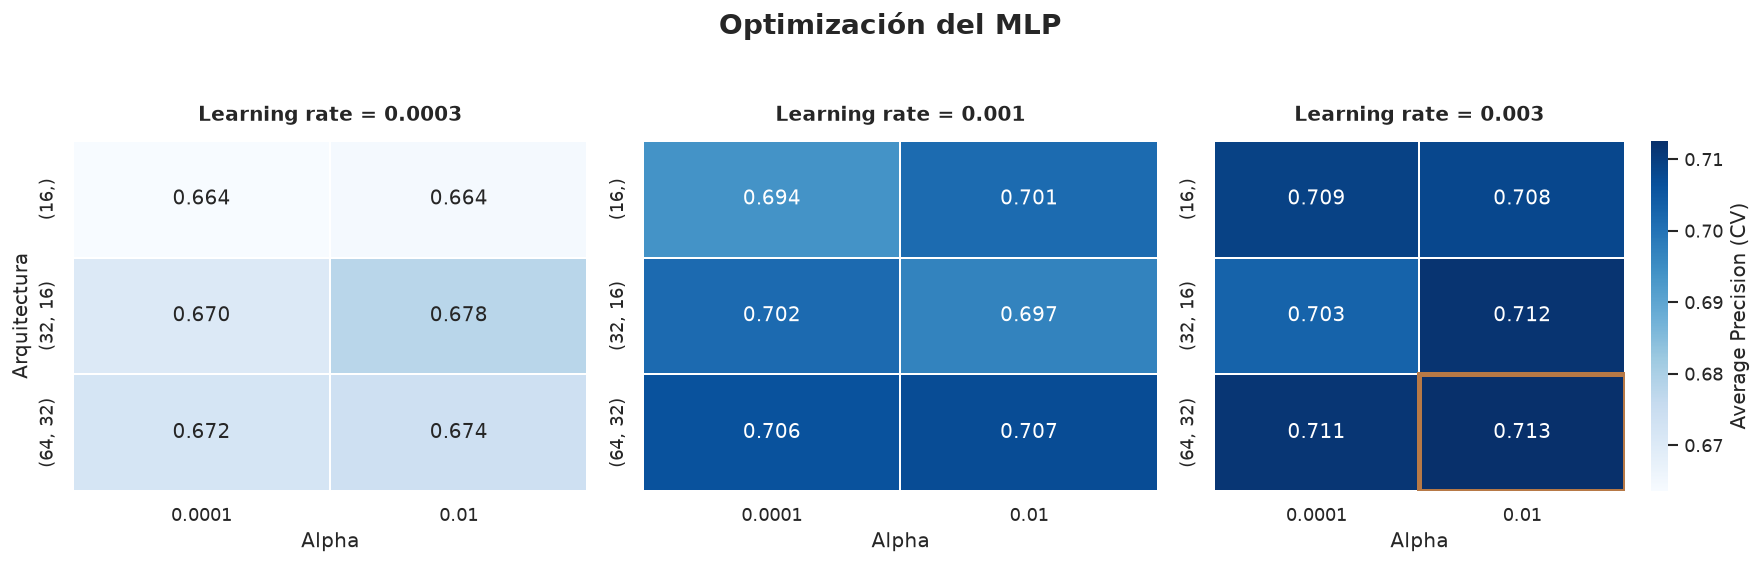

In [35]:
resultados_mlp = pd.DataFrame(busqueda_mlp.cv_results_)

resultados_mlp["Arquitectura"] = (
    resultados_mlp["param_clasificador__hidden_layer_sizes"]
    .astype(str)
)

resultados_mlp["Alpha"] = (
    resultados_mlp["param_clasificador__alpha"].astype(float)
)

resultados_mlp["Learning rate"] = (
    resultados_mlp["param_clasificador__learning_rate_init"]
    .astype(float)
)

arquitecturas = ["(16,)", "(32, 16)", "(64, 32)"]
alfas = [0.0001, 0.01]
tasas = [0.0003, 0.001, 0.003]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

vmin = resultados_mlp["mean_test_score"].min()
vmax = resultados_mlp["mean_test_score"].max()

for i, (ax, tasa) in enumerate(zip(axes, tasas)):

    subset = resultados_mlp[
        resultados_mlp["Learning rate"] == tasa
    ]

    mapa = subset.pivot(
        index="Arquitectura",
        columns="Alpha",
        values="mean_test_score"
    ).reindex(
        index=arquitecturas,
        columns=alfas
    )

    sns.heatmap(
        mapa,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        linewidths=1,
        linecolor="white",
        cbar=(i == 2),
        cbar_kws={"label": "Average Precision (CV)"},
        ax=ax
    )

    ax.set_title(f"Learning rate = {tasa}", pad=12)
    ax.set_xlabel("Alpha")
    ax.set_ylabel("Arquitectura" if i == 0 else "")

    if tasa == busqueda_mlp.best_params_[
        "clasificador__learning_rate_init"
    ]:
        mejor_fila, mejor_columna = np.unravel_index(
            np.nanargmax(mapa.to_numpy()),
            mapa.shape
        )

        ax.add_patch(
            plt.Rectangle(
                (mejor_columna, mejor_fila),
                1, 1,
                fill=False,
                edgecolor="#B77946",
                linewidth=3
            )
        )

fig.suptitle(
    "Optimización del MLP",
    fontsize=17,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración tiene un **AP de 0,713**, frente al 0,702 inicial, con arquitectura (64, 32), learning_rate_init=0.003 y alpha=0.01.
- La tasa de aprendizaje es el parámetro con mayor influencia: los valores más altos ofrecen resultados mejores.
- La arquitectura más grande y el mayor valor de alpha también aparecen en la mejor configuración, aunque sus diferencias respecto a otras alternativas son pequeñas.

**Decisión:** agrandamos el rango de la tasa de aprendizaje y probamos una arquitectura mayor, manteniendo una búsqueda
reducida para controlar el coste computacional.

#### Refinamiento de hiperparámetros

Vamos a hacer una segunda búsqueda con tasas de aprendizaje más altas, una arquitectura de mayor tamaño y regularizaciones más intensas.

In [36]:
parametros_mlp_refinados = {
    "clasificador__hidden_layer_sizes": [
        (64, 32), (128, 64)
    ],
    "clasificador__learning_rate_init": [
        0.003, 0.006, 0.01
    ],
    "clasificador__alpha": [
        0.01, 0.1
    ]
}

busqueda_mlp_refinada = GridSearchCV(
    estimator=modelo_mlp,
    param_grid=parametros_mlp_refinados,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_mlp_refinada.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_mlp_refinada.best_params_)

print(f"\nAP inicial: {resumen_base.loc['MLP', 'AP_media']:.3f}")
print(f"AP primera búsqueda: {busqueda_mlp.best_score_:.3f}")
print(f"AP refinamiento: {busqueda_mlp_refinada.best_score_:.3f}")

Mejores hiperparámetros:
{'clasificador__alpha': 0.1, 'clasificador__hidden_layer_sizes': (64, 32), 'clasificador__learning_rate_init': 0.01}

AP inicial: 0.702
AP primera búsqueda: 0.713
AP refinamiento: 0.722


#### Resultados del refinamiento

Vamos a representar el Average Precision de las 12 configuraciones mediante tres mapas de calor con una escala común.

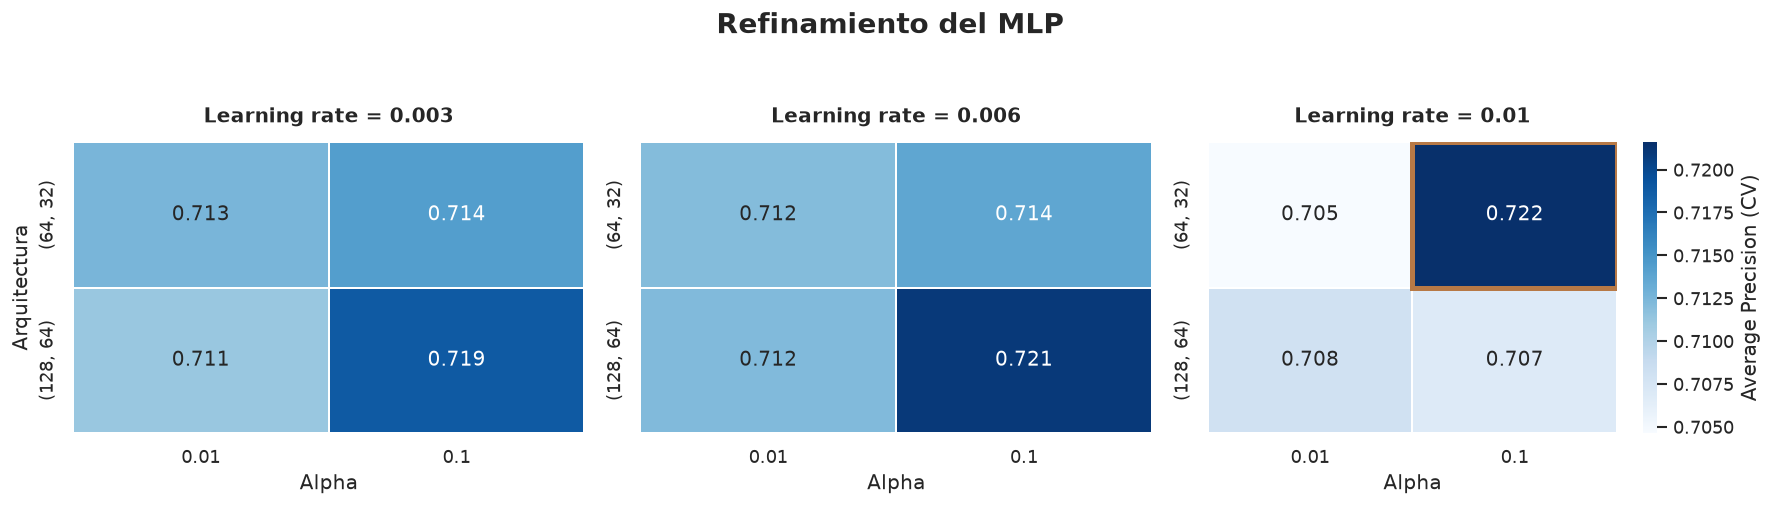

In [37]:
resultados_mlp_ref = pd.DataFrame(
    busqueda_mlp_refinada.cv_results_
)

resultados_mlp_ref["Arquitectura"] = (
    resultados_mlp_ref[
        "param_clasificador__hidden_layer_sizes"
    ].astype(str)
)

resultados_mlp_ref["Alpha"] = (
    resultados_mlp_ref[
        "param_clasificador__alpha"
    ].astype(float)
)

resultados_mlp_ref["Learning rate"] = (
    resultados_mlp_ref[
        "param_clasificador__learning_rate_init"
    ].astype(float)
)

arquitecturas = ["(64, 32)", "(128, 64)"]
alfas = [0.01, 0.1]
tasas = [0.003, 0.006, 0.01]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

vmin = resultados_mlp_ref["mean_test_score"].min()
vmax = resultados_mlp_ref["mean_test_score"].max()

for i, (ax, tasa) in enumerate(zip(axes, tasas)):

    subset = resultados_mlp_ref[
        resultados_mlp_ref["Learning rate"] == tasa
    ]

    mapa = subset.pivot(
        index="Arquitectura",
        columns="Alpha",
        values="mean_test_score"
    ).reindex(
        index=arquitecturas,
        columns=alfas
    )

    sns.heatmap(
        mapa,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        linewidths=1,
        linecolor="white",
        cbar=(i == 2),
        cbar_kws={"label": "Average Precision (CV)"},
        ax=ax
    )

    if tasa == busqueda_mlp_refinada.best_params_[
        "clasificador__learning_rate_init"
    ]:
        fila, columna = np.unravel_index(
            np.nanargmax(mapa.to_numpy()),
            mapa.shape
        )

        ax.add_patch(
            plt.Rectangle(
                (columna, fila),
                1, 1,
                fill=False,
                edgecolor="#B77946",
                linewidth=3
            )
        )

    ax.set_title(f"Learning rate = {tasa}", pad=12)
    ax.set_xlabel("Alpha")
    ax.set_ylabel("Arquitectura" if i == 0 else "")

fig.suptitle(
    "Refinamiento del MLP",
    fontsize=17,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración tiene un **AP de 0,722**, usa la arquitectura (64, 32), learning_rate_init=0.01 y alpha=0.1.
- Los mejores resultados tienen tasas de aprendizaje y regularizaciones mayores a las exploradas inicialmente.
- No podemos decir que la arquitectura (128, 64) presenta una ventaja consistente frente a (64, 32).

**Decisión:** dejamos la arquitectura (64, 32) y aumentamos únicamente los rangos de learning_rate_init y alpha.

#### Refinamiento final del MLP

En la segunda búsqueda hemos vuelto a ver que los mejores resultados de Average Precision estan el los valores más altos de la tasa de aprendizaje y de la refularixación.

Por ello vamos a dejar la arquitectura (64, 32), que tiene buenos resultados con menor complejidad, y ampliamos los rangos de learning_rate_init y alpha.

In [38]:
from sklearn.base import clone

modelo_mlp_final = clone(modelo_mlp).set_params(
    clasificador__hidden_layer_sizes=(64, 32)
)

parametros_mlp_final = {
    "clasificador__learning_rate_init": [
        0.006, 0.01, 0.015, 0.02
    ],
    "clasificador__alpha": [
        0.03, 0.1, 0.3
    ]
}

busqueda_mlp_final = GridSearchCV(
    estimator=modelo_mlp_final,
    param_grid=parametros_mlp_final,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_mlp_final.fit(X_train, y_train)

print("Mejores hiperparámetros:")
print(busqueda_mlp_final.best_params_)

print(f"\nAP inicial: {resumen_base.loc['MLP', 'AP_media']:.3f}")
print(f"AP primera búsqueda: {busqueda_mlp.best_score_:.3f}")
print(f"AP segunda búsqueda: {busqueda_mlp_refinada.best_score_:.3f}")
print(f"AP refinamiento final: {busqueda_mlp_final.best_score_:.3f}")

Mejores hiperparámetros:
{'clasificador__alpha': 0.1, 'clasificador__learning_rate_init': 0.01}

AP inicial: 0.702
AP primera búsqueda: 0.713
AP segunda búsqueda: 0.722
AP refinamiento final: 0.722


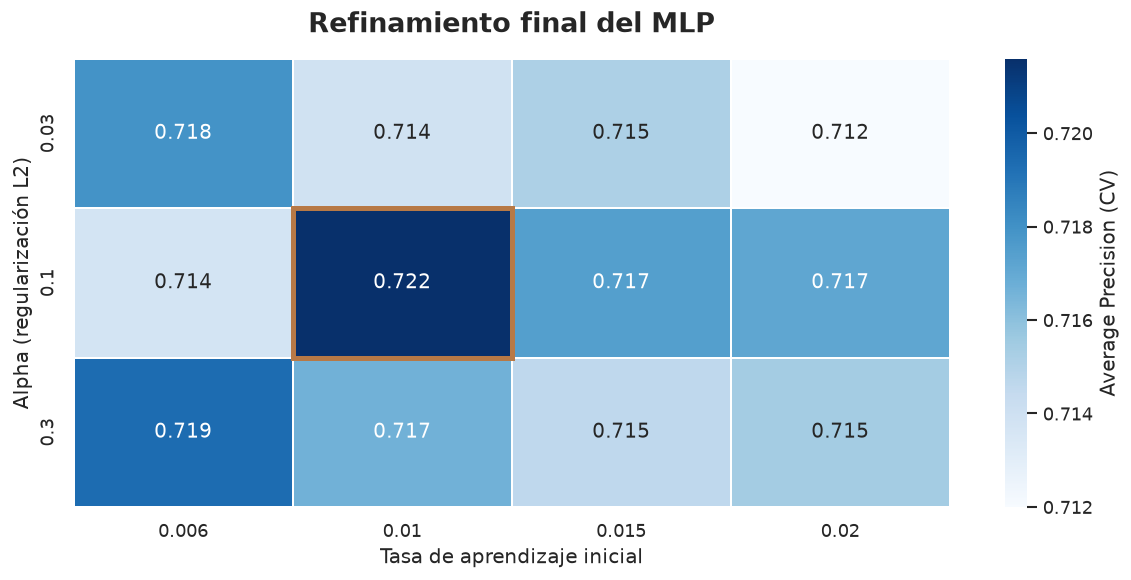

In [40]:
# Heatmap del refinamiento final del MLP

resultados_mlp_final = pd.DataFrame(
    busqueda_mlp_final.cv_results_
)

mapa_mlp_final = resultados_mlp_final.pivot(
    index="param_clasificador__alpha",
    columns="param_clasificador__learning_rate_init",
    values="mean_test_score"
).reindex(
    index=[0.03, 0.1, 0.3],
    columns=[0.006, 0.01, 0.015, 0.02]
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.heatmap(
    mapa_mlp_final,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Average Precision (CV)"},
    ax=ax
)

mejor_fila, mejor_columna = np.unravel_index(
    np.nanargmax(mapa_mlp_final.to_numpy()),
    mapa_mlp_final.shape
)

ax.add_patch(
    plt.Rectangle(
        (mejor_columna, mejor_fila),
        1, 1,
        fill=False,
        edgecolor="#B77946",
        linewidth=3
    )
)

ax.set_title(
    "Refinamiento final del MLP",
    fontsize=16,
    pad=16
)

ax.set_xlabel("Tasa de aprendizaje inicial")
ax.set_ylabel("Alpha (regularización L2)")

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración sigue siendo **(64, 32) neuronas**, **learning_rate_init=0.01** y **alpha=0.1**, con un AP de **0,722**.
- Subir la tasa de aprendizaje por encima de 0,01 o la regularización por encima de 0,1 no mejora los resultados.
- Las configuraciones cercanas tienen rendimientos similares, lo que indica que el modelo se mantiene estable en esta zona.

**Decisión:** finalizamos la optimización del MLP y nos quedamos con la mejor configuración encontrada.

### 3.4. CatBoost

CatBoost es un algoritmo de Gradient Boosting que construye árboles de decisión de forma secuencial. Una de sus ventajas es que permite tratar directamente con variables categóricas.

Para intentar mejorar sus resultados, vamos a probar diferentes valores de tres hiperparámetros:
- **depth:** profundidad de los árboles. Cuanto mayor sea, más complejas pueden ser las relaciones que aprende el modelo.

- **learning_rate:** controla cuánto influye cada nuevo árbol en el resultado final del modelo.

- **iterations:** número de árboles que se construyen durante el entrenamiento. Esta parámetro está  relacionado con la tasa de aprendizaje ya que los valores más bajos suelen necesitar un mayor número de iteraciones.

Para encontrar la mejor combinación vamos a usar GridSearchCV con cinco folds estratificados, seleccionando la configuración de mayor Average Precision.

In [41]:
parametros_catboost = {
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.07, 0.12],
    "iterations": [300, 600]
}

busqueda_catboost = GridSearchCV(
    estimator=modelo_catboost,
    param_grid=parametros_catboost,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_catboost.fit(
    X_train_cat,
    y_train,
    cat_features=variables_categoricas
)

print("Mejores hiperparámetros:")
print(busqueda_catboost.best_params_)

print(f"\nAP inicial: {resumen_base.loc['CatBoost', 'AP_media']:.3f}")
print(f"AP optimizado (CV): {busqueda_catboost.best_score_:.3f}")

Mejores hiperparámetros:
{'depth': 8, 'iterations': 300, 'learning_rate': 0.03}

AP inicial: 0.742
AP optimizado (CV): 0.752


#### Resultados de la búsqueda

Para comparar las 18 configuraciones hemos representado los resultados de Average Precision en dos mapas de calor, uno para cada número de iteraciones.

En cada mapa podemos ver cómo afectan la profundidad y la tasa de aprendizaje al rendimiento del modelo. Usamos la misma escala de colores en ambos para que sea más fácil compara los resultados.

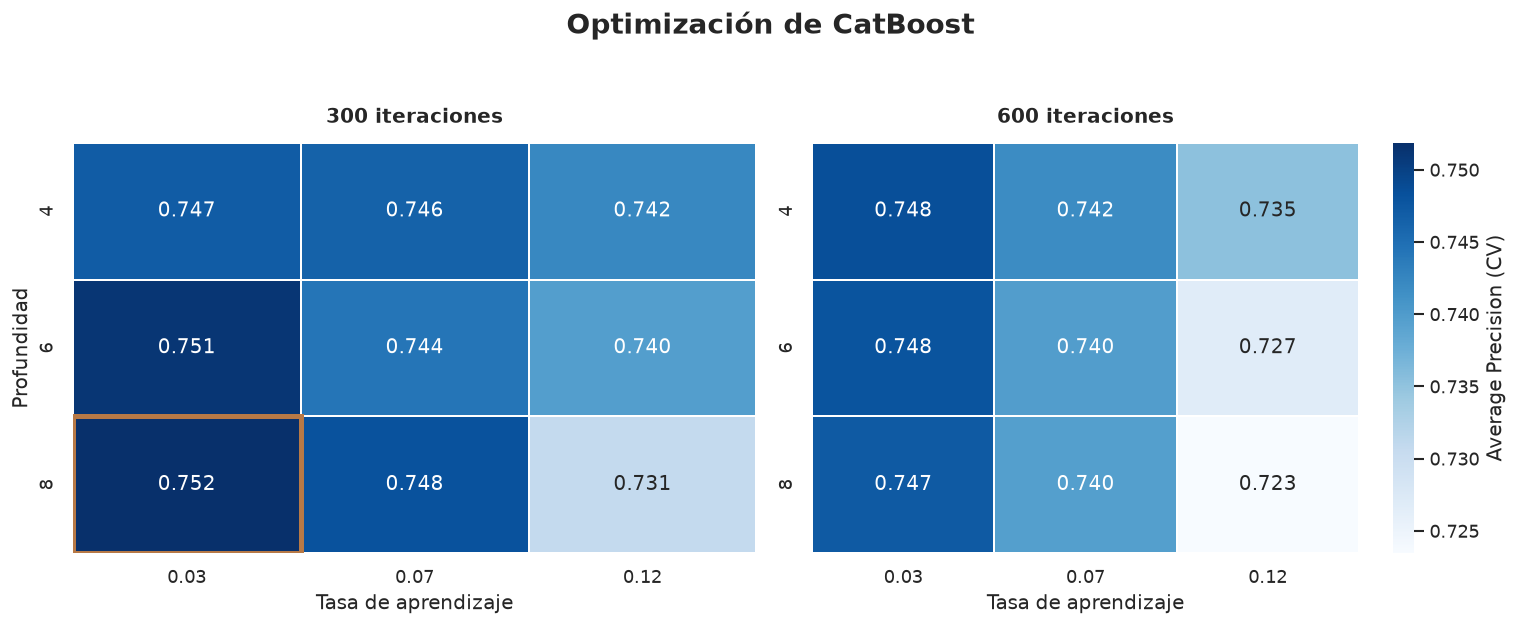

In [42]:
resultados_cb = pd.DataFrame(busqueda_catboost.cv_results_)

resultados_cb["Profundidad"] = resultados_cb["param_depth"].astype(int)
resultados_cb["Learning rate"] = resultados_cb["param_learning_rate"].astype(float)
resultados_cb["Iteraciones"] = resultados_cb["param_iterations"].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

vmin = resultados_cb["mean_test_score"].min()
vmax = resultados_cb["mean_test_score"].max()

for i, (ax, iteraciones) in enumerate(zip(axes, [300, 600])):

    subset = resultados_cb[
        resultados_cb["Iteraciones"] == iteraciones
    ]

    mapa = subset.pivot(
        index="Profundidad",
        columns="Learning rate",
        values="mean_test_score"
    ).reindex(
        index=[4, 6, 8],
        columns=[0.03, 0.07, 0.12]
    )

    sns.heatmap(
        mapa,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        linewidths=1,
        linecolor="white",
        cbar=(i == 1),
        cbar_kws={"label": "Average Precision (CV)"},
        ax=ax
    )

    # Resaltar la mejor configuración global
    if iteraciones == busqueda_catboost.best_params_["iterations"]:

        fila, columna = np.unravel_index(
            np.nanargmax(mapa.to_numpy()),
            mapa.shape
        )

        ax.add_patch(
            plt.Rectangle(
                (columna, fila),
                1, 1,
                fill=False,
                edgecolor="#B77946",
                linewidth=3
            )
        )

    ax.set_title(f"{iteraciones} iteraciones", pad=12)
    ax.set_xlabel("Tasa de aprendizaje")
    ax.set_ylabel("Profundidad" if i == 0 else "")

fig.suptitle(
    "Optimización de CatBoost",
    fontsize=17,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor configuración tiene un AP de **0,752**, frente al 0,742 inicial, con profundidad 8, learning_rate=0.03 y 300 iteraciones.
- Las tasas de aprendizaje más bajas tienen mejores resultados, sobre todo en los árboles más profundos.
- Aumentar las iteraciones de 300 a 600 no mejora mucho el modelo.

**Decisión:** intentamos mejorar la búsqueda probando profundidades superiores, tasas de aprendizaje inferiores y menos iteraciones.

#### Refinamiento de hiperparámetros

En esta segunda búsqueda miramos si árboles más profundos, tasas de aprendizaje menores o menos iteraciones mejoran el rendimiento.

Seguimos usando Average Precision como criterio de selección.

In [43]:
parametros_catboost_ref = {
    "depth": [6, 8, 10],
    "learning_rate": [0.015, 0.03],
    "iterations": [200, 300]
}

busqueda_catboost_ref = GridSearchCV(
    estimator=modelo_catboost,
    param_grid=parametros_catboost_ref,
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_catboost_ref.fit(
    X_train_cat,
    y_train,
    cat_features=variables_categoricas
)

print("Mejores hiperparámetros:")
print(busqueda_catboost_ref.best_params_)

print(f"\nAP inicial: {resumen_base.loc['CatBoost', 'AP_media']:.3f}")
print(f"AP primera búsqueda: {busqueda_catboost.best_score_:.3f}")
print(f"AP refinamiento: {busqueda_catboost_ref.best_score_:.3f}")

Mejores hiperparámetros:
{'depth': 8, 'iterations': 200, 'learning_rate': 0.03}

AP inicial: 0.742
AP primera búsqueda: 0.752
AP refinamiento: 0.752


#### Resultados del refinamiento

Hemos vuelto a representar las 12 configuraciones mediante dos mapas de calor, uno por cada número de iteraciones.

Hemos usado una escala común para comparar los resultados y poder identificar si la mejora se concentra en alguna región de hiperparámetros.

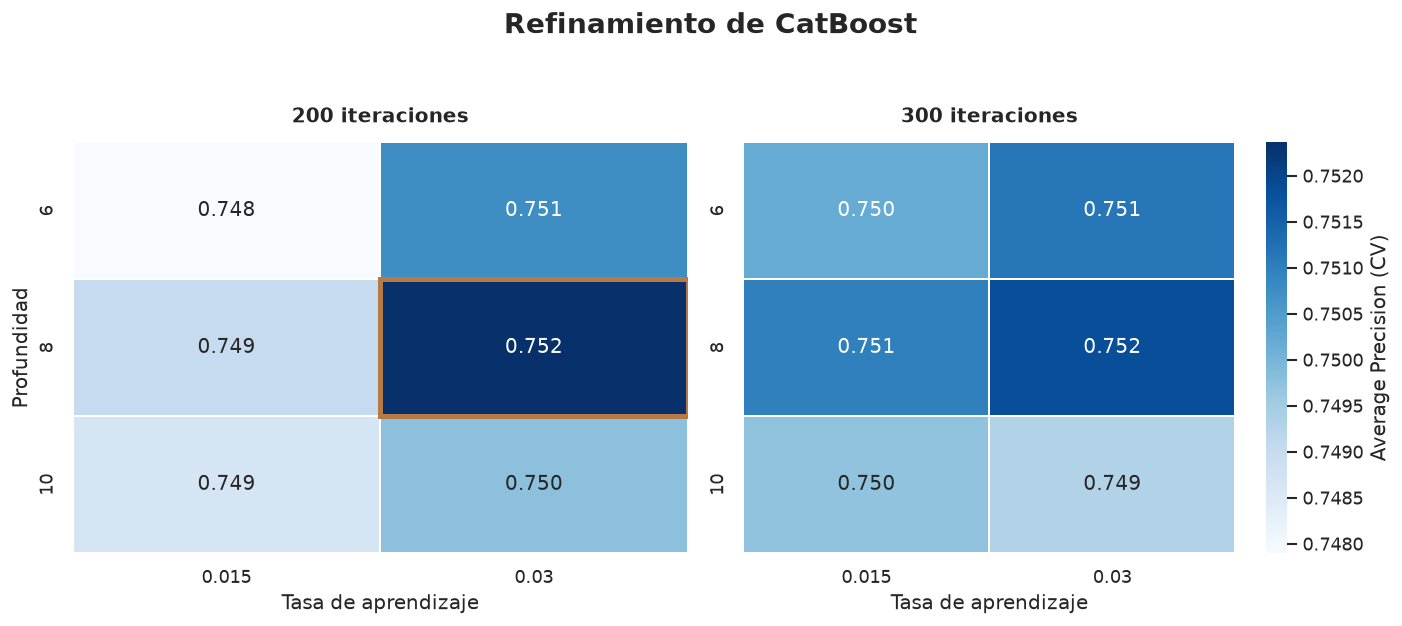

In [44]:
resultados_cb_ref = pd.DataFrame(
    busqueda_catboost_ref.cv_results_
)

resultados_cb_ref["Profundidad"] = (
    resultados_cb_ref["param_depth"].astype(int)
)

resultados_cb_ref["Learning rate"] = (
    resultados_cb_ref["param_learning_rate"].astype(float)
)

resultados_cb_ref["Iteraciones"] = (
    resultados_cb_ref["param_iterations"].astype(int)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

vmin = resultados_cb_ref["mean_test_score"].min()
vmax = resultados_cb_ref["mean_test_score"].max()

for i, (ax, iteraciones) in enumerate(zip(axes, [200, 300])):

    subset = resultados_cb_ref[
        resultados_cb_ref["Iteraciones"] == iteraciones
    ]

    mapa = subset.pivot(
        index="Profundidad",
        columns="Learning rate",
        values="mean_test_score"
    ).reindex(
        index=[6, 8, 10],
        columns=[0.015, 0.03]
    )

    sns.heatmap(
        mapa,
        annot=True,
        fmt=".3f",
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        linewidths=1,
        linecolor="white",
        cbar=(i == 1),
        cbar_kws={"label": "Average Precision (CV)"},
        ax=ax
    )

    # Resaltar la mejor configuración global
    if iteraciones == busqueda_catboost_ref.best_params_["iterations"]:

        fila, columna = np.unravel_index(
            np.nanargmax(mapa.to_numpy()),
            mapa.shape
        )

        ax.add_patch(
            plt.Rectangle(
                (columna, fila),
                1, 1,
                fill=False,
                edgecolor="#B77946",
                linewidth=3
            )
        )

    ax.set_title(f"{iteraciones} iteraciones", pad=12)
    ax.set_xlabel("Tasa de aprendizaje")
    ax.set_ylabel("Profundidad" if i == 0 else "")

fig.suptitle(
    "Refinamiento de CatBoost",
    fontsize=17,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

**Interpretación**

- El mejor AP sigue estando alrededor de **0,752**. Probar menos iteraciones, menores tasas de aprendizaje y árboles más profundos no mejora el modelo demasiado.
- La profundidad 8 y el learning rate de 0,03 siguen teniendo unos buenos resultados.
- El rendimiento es estable entre 200 y 300 iteraciones.

**Decisión:** nos quedamos con la mejor configuración encontrada y realizamos una última comprobación de la regularización L2.

#### Ajuste final de la regularización L2

Duranete las búsquedas anteriores hemos encontrado una región estable para la profundidad, tasa de aprendizaje y número de árboles.

Como último experimento, vamos a ver el efecto de `l2_leaf_reg`, que controla la regularización de los valores de las hojas.

Fijamos depth=8, learning_rate=0.03 e iterations=300, incluyendo el valor predeterminado de regularización para compararlo con alternativas más débiles y más intensas.

In [45]:
from sklearn.base import clone

modelo_catboost_l2 = clone(modelo_catboost).set_params(
    depth=8,
    learning_rate=0.03,
    iterations=300
)

busqueda_catboost_l2 = GridSearchCV(
    estimator=modelo_catboost_l2,
    param_grid={"l2_leaf_reg": [1, 3, 6, 10]},
    scoring="average_precision",
    cv=cv,
    n_jobs=1,
    error_score="raise"
)

busqueda_catboost_l2.fit(
    X_train_cat,
    y_train,
    cat_features=variables_categoricas
)

print("Mejor regularización:")
print(busqueda_catboost_l2.best_params_)

print(f"\nAP inicial: {resumen_base.loc['CatBoost', 'AP_media']:.4f}")
print(f"AP primera búsqueda: {busqueda_catboost.best_score_:.4f}")
print(f"AP segundo refinamiento: {busqueda_catboost_ref.best_score_:.4f}")
print(f"AP búsqueda L2: {busqueda_catboost_l2.best_score_:.4f}")

Mejor regularización:
{'l2_leaf_reg': 3}

AP inicial: 0.7422
AP primera búsqueda: 0.7519
AP segundo refinamiento: 0.7524
AP búsqueda L2: 0.7519


#### Resultados del ajuste de regularización

Hemos comparado el Average Precision obtenido con diferentes intensidades de regularización L2.

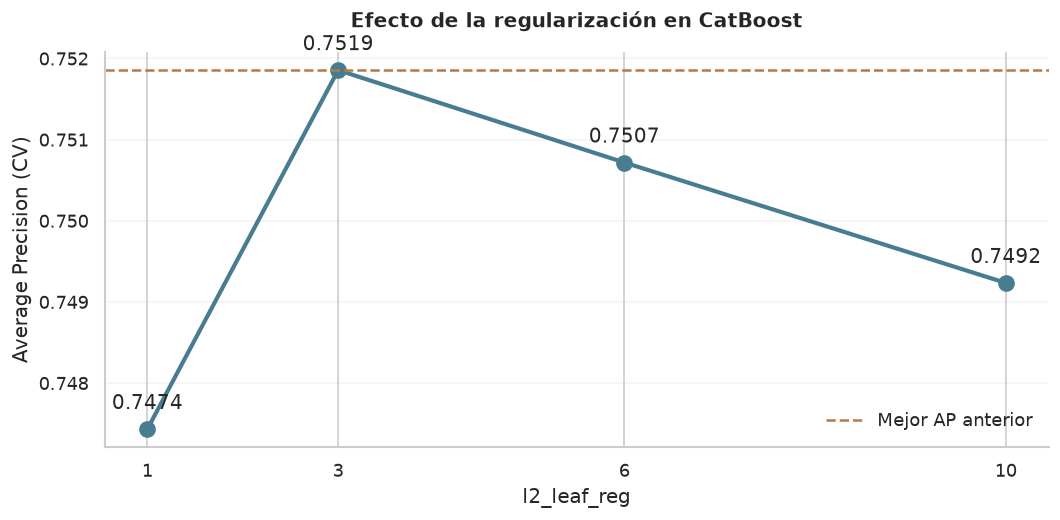

In [46]:
resultados_l2 = pd.DataFrame(
    busqueda_catboost_l2.cv_results_
)

resultados_l2["L2"] = resultados_l2[
    "param_l2_leaf_reg"
].astype(float)

resultados_l2 = resultados_l2.sort_values("L2")

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(
    resultados_l2["L2"],
    resultados_l2["mean_test_score"],
    marker="o",
    markersize=9,
    linewidth=2.5,
    color="#487D91"
)

ax.axhline(
    busqueda_catboost.best_score_,
    color="#B77946",
    linestyle="--",
    label="Mejor AP anterior"
)

for _, fila in resultados_l2.iterrows():
    ax.annotate(
        f'{fila["mean_test_score"]:.4f}',
        (fila["L2"], fila["mean_test_score"]),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center"
    )

ax.set_xticks([1, 3, 6, 10])
ax.set_xlabel("l2_leaf_reg")
ax.set_ylabel("Average Precision (CV)")
ax.set_title("Efecto de la regularización en CatBoost", pad=15)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

**Interpretación**

- La mejor regularización es **l2_leaf_reg=3**, con un AP de **0,7519**, el mismo resultado que en las búsquedas anteriores.
- Una regularización menor (1) o mayor (6 y 10) dismuniye un poco el rendimiento.

**Decisión:** acabamos esta optimización de CatBoost con depth=8, learning_rate=0.03, iterations=300 y l2_leaf_reg=3.
No hacemos más búsquedas.

## 4. Comparación de modelos optimizados

Ahora vamos a comparar el Average Precision obtenido por los cuatro algoritmos antes y después de la optimización de hiperparámetros.

Vamos a utilizar los resultados de validación cruzada ya calculados, sin volver a entrenar los modelos.

In [47]:
mejores_busquedas = {
    "Regresión logística": busqueda_lr,
    "Random Forest": busqueda_rf_refinada,
    "MLP": busqueda_mlp_final,
    "CatBoost": busqueda_catboost_l2
}

comparacion = pd.DataFrame({
    "AP inicial": resumen_base["AP_media"],
    "AP optimizado": pd.Series({
        nombre: busqueda.best_score_
        for nombre, busqueda in mejores_busquedas.items()
    })
})

comparacion["Mejora"] = (
    comparacion["AP optimizado"] - comparacion["AP inicial"]
)

comparacion = comparacion.sort_values(
    "AP optimizado", ascending=False
)

display(
    comparacion.style
    .format("{:.4f}")
    .background_gradient(
        subset=["AP optimizado"],
        cmap="Blues"
    )
)

,AP inicial,AP optimizado,Mejora
Random Forest,0.7471,0.7556,0.0085
CatBoost,0.7422,0.7519,0.0096
MLP,0.7016,0.7216,0.0200
Regresión logística,0.6356,0.6514,0.0158


### 4.1. Comparación visual de Average Precision

Hemos representado el rendimiento inicial y optimizado de cada algoritmo para poder ver las diferencias entre modelos y las mejoras obtenidas mediante la búsqueda de hiperparámetros.

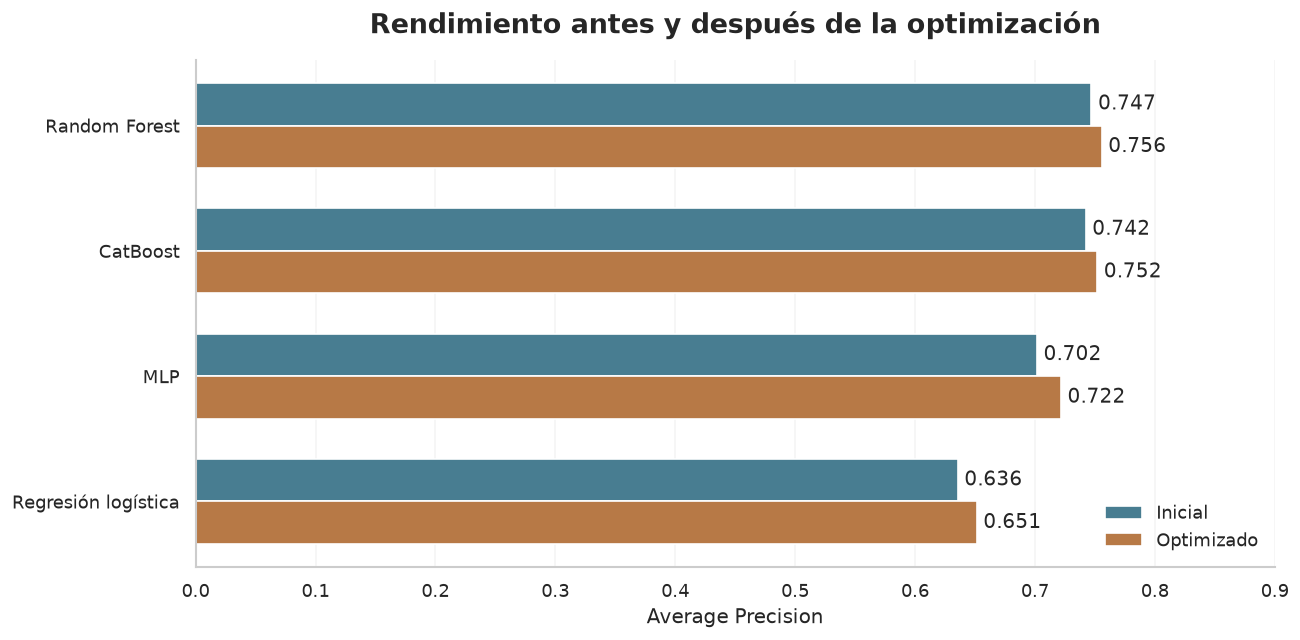

In [48]:
fig, ax = plt.subplots(figsize=(11, 5.5))

y = np.arange(len(comparacion))
ancho = 0.34

barras_iniciales = ax.barh(
    y - ancho / 2,
    comparacion["AP inicial"],
    height=ancho,
    color="#487D91",
    label="Inicial"
)

barras_optimizadas = ax.barh(
    y + ancho / 2,
    comparacion["AP optimizado"],
    height=ancho,
    color="#B77946",
    label="Optimizado"
)

ax.bar_label(barras_iniciales, fmt="%.3f", padding=4)
ax.bar_label(barras_optimizadas, fmt="%.3f", padding=4)

ax.set_yticks(y)
ax.set_yticklabels(comparacion.index)
ax.invert_yaxis()

ax.set_xlim(0, 0.9)
ax.set_xlabel("Average Precision")
ax.set_title(
    "Rendimiento antes y después de la optimización",
    fontsize=16,
    pad=16
)

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

**Interpretación**

- **Random Forest** consigue el mayor Average Precision (0,7556), seguido por **CatBoost** (0,7519). La diferencia entre ambos modelos es de 0,0037, lo que es demasiado pequeña para afirmar que uno sea claramente mejor.

- **MLP** es el modelo que más mejora depués de ajustar sus hiperparámetros (+0,0200). Aún así su resultado final (0,7216) sigue siendo menor que el de ambos de los modelos del punto anterior.

- **Regresión logística** también mejora (0,6356 → 0,6514), pero es el que tiene el rendimiento más bajo.

**Decisión:** Random Forest y CatBoost son los modelos que mejores resultados obtienen. Mantendremos los cuatro como referencia, pero en los siguientes experimentos nos centraremos en intentar mejorar estos dos modelos.

Hay que tener en cuenta que estas puntuaciones se han calculado con los mimos folds que hemos utilizado para elegir los hiperparámetros. Por ello todavía no son una evaluación final independiente y podrían ser algo optimistas.